# Predicting one drone

How to score a single drone with the model fitted in `drone_survival.ipynb`.

A forecast needs three things:

1. the saved model (`models/best_cox.json` or `models/best_aft.json`);
2. the drone's 16 features, all fixed at commissioning;
3. its current age: flight hours already flown without a failure.

The age is not a feature. It enters only through the conditional survival \(S(a+u)/S(a)\): the chance of lasting \(u\) more hours given that the drone has already lasted \(a\).


## 1. Load the fitted model

`meta.json` records which model won on validation, the feature list, the horizon and the maintenance thresholds. `Model.load` restores the booster together with the state the curves need: the category vocabulary, the Breslow baseline and the frailty recalibration. `booster.load_model` alone would not be enough.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils import Model, hazard_bandwidth, remaining_life

META = json.loads(Path("artifacts/meta.json").read_text())
MODEL = Model.load(Path("models") / META["models"][META["best_name"]])

FEATURES = META["features"]
HORIZON = META["rul_horizon"]       # furthest the Cox baseline is supported, flight hours
WINDOW = META["rul_window"]         # look-ahead of the failure probability, flight hours
P_HIGH, P_MEDIUM = (META["priority_thresholds"][k] for k in ("high", "medium"))

print(f"{META['best_name']}, horizon {HORIZON:.0f} h, window {WINDOW:.0f} h")
print("recalibration:", MODEL.calibration)


Matplotlib is building the font cache; this may take a moment.


cox, horizon 1111 h, window 100 h
recalibration: {'frailty_variance': 0.2671968813692113, 'scale': 1.0501261484458901}


## 2. One row per drone

Build a one-row `DataFrame`. Categorical columns must use values seen in training (`meta.json` → `categories`); an unseen level is treated as missing. `is_refurbished` stays boolean. `duration_h` is the age in flight hours, not a model feature: `0` means a drone that has just been commissioned.

The row below is a real test drone, DR-003057, so the result can be checked against the notebook artifacts.


In [2]:
drone = pd.DataFrame(
    {
        "drone_id": ["DR-003057"],
        "model": ["quad_light"],
        "environment": ["urban"],
        "is_refurbished": [False],
        "initial_battery_cycles": [24],
        "firmware_major": [3],
        "maintenance_interval_h": [200],
        "operator_experience_yrs": [1.44],
        "daily_utilization_h": [0.75],
        "avg_flight_min": [23.5],
        "avg_payload_kg": [0.722],
        "payload_ratio": [0.722],
        "mean_temp_c": [0.3],
        "avg_humidity_pct": [48.7],
        "avg_wind_ms": [6.28],
        "hard_landings_per_100h": [5.02],
        "mean_vibration_g": [0.431],
        "duration_h": [193.5],
    }
)

missing = [f for f in FEATURES if f not in drone.columns]
print("missing features:", missing or "none")
drone[FEATURES + ["duration_h"]].T


missing features: none


,0
model,quad_light
environment,urban
is_refurbished,False
initial_battery_cycles,24
firmware_major,3
maintenance_interval_h,200
operator_experience_yrs,1.44
daily_utilization_h,0.75
avg_flight_min,23.5
avg_payload_kg,0.722


## 3. Survival from commissioning, \(S(t)\)

`survival` ignores the age and returns the probability of lasting beyond each time, measured from commissioning. One row in, one curve out.


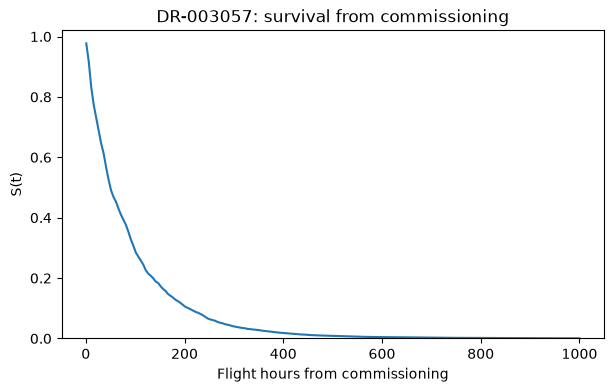

P(still flying at 200 h) = 10.7%


In [3]:
grid = np.linspace(1, 1000, 200)
survival = MODEL.survival(drone, grid)[0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, survival)
ax.set(xlabel="Flight hours from commissioning", ylabel="S(t)", ylim=(0, 1.02),
       title=f"{drone['drone_id'].iloc[0]}: survival from commissioning")
plt.show()

print(f"P(still flying at 200 h) = {np.interp(200, grid, survival):.1%}")


## 4. Remaining life at the current age

The maintenance forecast is conditional on the drone having already survived its age \(a\) = `duration_h`:

\[S(a+u \mid T > a) = S(a+u) / S(a).\]

`remaining_life` turns that curve into the numbers used by the dashboards:

- `p_fail_window` — probability of failing within the next `WINDOW` flight hours;
- `rul_q10`, `rul_median` — flight hours until the failure probability reaches 10% and 50%; `inf` when that does not happen within the horizon;
- `rmrl` — mean remaining life, capped at the horizon.

The same features at age 0 give a different forecast: the age changes the outlook even though nothing about the drone changed.


In [4]:
def maintenance_priority(p_fail: float) -> str:
    if p_fail >= P_HIGH:
        return "High"
    return "Medium" if p_fail >= P_MEDIUM else "Low"


forecast = remaining_life(MODEL, drone, horizon=HORIZON, window=WINDOW)
forecast["priority"] = forecast["p_fail_window"].map(maintenance_priority)

as_new = drone.copy()
as_new["duration_h"] = 0.0
new_forecast = remaining_life(MODEL, as_new, horizon=HORIZON, window=WINDOW)

pd.concat(
    {"at current age": forecast, "same drone, age 0": new_forecast},
    names=["when"],
).round(3)


,,drone_id,age_h,rul_q10,rul_median,rmrl,p_fail_window,priority
when,,,,,,,,
at current age,0,DR-003057,193.5,9.999,69.993,114.093,0.625,High
"same drone, age 0",0,DR-003057,0.0,7.777,49.995,86.078,0.711,NaN


## 5. The conditional curve

The median remaining life is where the curve crosses 0.5; the failure probability in the window is one minus the curve at `WINDOW` hours.


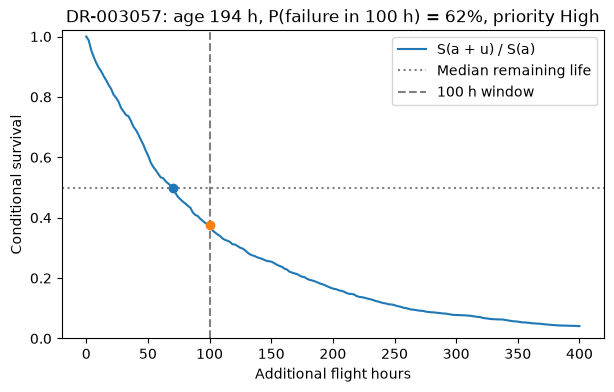

In [5]:
ahead = np.linspace(0, 400, 200)
conditional = MODEL.conditional_survival(drone, drone["duration_h"], ahead)[0]
row = forecast.iloc[0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ahead, conditional, label="S(a + u) / S(a)")
ax.axhline(0.5, color="grey", linestyle=":", label="Median remaining life")
ax.axvline(WINDOW, color="grey", linestyle="--", label=f"{WINDOW:.0f} h window")
ax.scatter([row["rul_median"]], [0.5], zorder=3)
ax.scatter([WINDOW], [1 - row["p_fail_window"]], zorder=3)
ax.set(
    xlabel="Additional flight hours",
    ylabel="Conditional survival",
    ylim=(0, 1.02),
    title=(f"{row['drone_id']}: age {row['age_h']:.0f} h, "
           f"P(failure in {WINDOW:.0f} h) = {row['p_fail_window']:.0%}, "
           f"priority {row['priority']}"),
)
ax.legend()
plt.show()


## 6. Where the risk comes from: the hazard

`hazard` is the failure rate per flight hour at each time, for this drone's features. For Cox it is the Breslow baseline smoothed with a kernel and multiplied by the drone's risk; the bandwidth only sets that smoothing. It is taken here from the training failure times stored in the model.


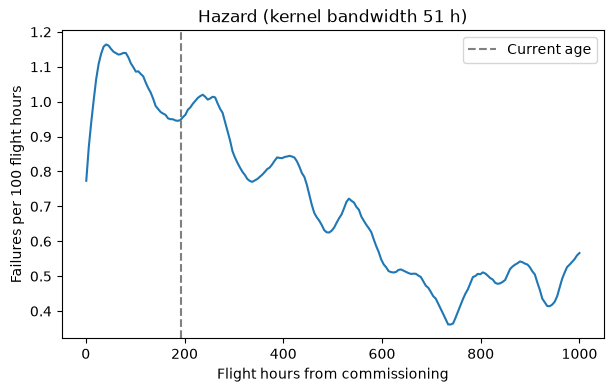

In [6]:
event_times = MODEL._breslow[0]
bandwidth = hazard_bandwidth(event_times, np.ones(len(event_times), dtype=bool))
hazard = MODEL.hazard(drone, grid, bandwidth)[0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, 100 * hazard)
ax.axvline(drone["duration_h"].iloc[0], color="grey", linestyle="--", label="Current age")
ax.set(
    xlabel="Flight hours from commissioning",
    ylabel="Failures per 100 flight hours",
    title=f"Hazard (kernel bandwidth {bandwidth:.0f} h)",
)
ax.legend()
plt.show()


## 7. Change one feature

Copy the row, edit a feature and score again at the same age. This is what the "what if" box of the drone card does. It is a model counterfactual: the other features stay as they are, including the ones that move together with it in reality.


In [7]:
scenario = drone.copy()
scenario["operator_experience_yrs"] = 8.0

compared = pd.concat(
    {
        "now": forecast,
        "8 years of experience": remaining_life(MODEL, scenario, HORIZON, WINDOW),
    },
    names=["scenario"],
)
compared.round(3)


,,drone_id,age_h,rul_q10,rul_median,rmrl,p_fail_window,priority
scenario,,,,,,,,
now,0,DR-003057,193.5,9.999,69.993,114.093,0.625,High
8 years of experience,0,DR-003057,193.5,12.221,78.881,129.351,0.579,NaN


## 8. Check against the notebook

The pipeline stores the same forecast in `artifacts/predictions.parquet`. Scoring the row here and reading the stored row must agree.


In [8]:
stored = pd.read_parquet("artifacts/predictions.parquet").set_index("drone_id").loc["DR-003057"]
check = pd.DataFrame(
    {
        "here": forecast[["p_fail_window", "rul_median", "rul_q10", "rmrl"]].iloc[0],
        "notebook": stored[["p_fail_window", "rul_median", "rul_q10", "rmrl"]],
    }
)
check["difference"] = check["here"] - check["notebook"]
check.round(6)


,here,notebook,difference
p_fail_window,0.624961,0.624961,0.0
rul_median,69.993000,69.993,0.0
rul_q10,9.999000,9.999,0.0
rmrl,114.092781,114.092781,0.0
